En este notebook se calcula la autocorrelación de la serie de tiempo de la magnetización para el algoritmo de Metropolis

In [6]:
using LinearAlgebra
using Statistics
using Plots

In [3]:
function get_energy(lattice, J=1)
    N, M = size(lattice)
    energy = 0.0

    @inbounds @simd for i in 1:N
        for j in 1:M 
            neighbors = 0

            #vecino de arriba
            neighbors += (i > 1) ? lattice[i-1, j] : lattice[N, j]
            # vecino de abajo
            neighbors += (i < N) ? lattice[i+1, j] : lattice[1, j]
            # vecino de la izquierda
            neighbors += (j > 1) ? lattice[i, j-1] : lattice[i, M]
            # vecino de la derecha
            neighbors += (j < M) ? lattice[i, j+1] : lattice[i, 1]

            energy -= J * lattice[i, j] * neighbors
        end
    end

    return energy / 2.0
end

function metropolis(spin_arr, times, T, energy, J=1, K=1)
    spin_arr = copy(spin_arr)
    net_spins = zeros(times)
    net_energy = zeros(times)
    N, M = size(spin_arr)
    beta = 1/(K*T)
    snapshots = []

    pasos_snapshot = Set([
        1, 
        1 + div(times, 6), 
        1 + div(2*times, 6), 
        1 + div(3*times, 6), 
        1+ div(4*times, 6),
        times
    ])

    current_net_spin = sum(spin_arr)

    for t in 1:times
        # Elegimos un punto random en el array
        x = rand(1:N)
        y = rand(1:M)
        spin_i = spin_arr[x, y]
        spin_f = -1*spin_i

        E_i = 0
        E_f = 0

        #aplicamos los cambios en la energía
        if x > 1
            E_i += -J * spin_i * spin_arr[x-1, y]
            E_f += -J * spin_f * spin_arr[x-1, y]
        elseif x == 1
            E_i += -J * spin_i * spin_arr[N, y]
            E_f += -J * spin_f * spin_arr[N, y]
        end
        if x < N
            E_i += -J * spin_i * spin_arr[x+1, y]
            E_f += -J * spin_f * spin_arr[x+1, y]
        elseif x == N
            E_i += -J * spin_i * spin_arr[1, y]
            E_f += -J * spin_f * spin_arr[1, y]
        end
        if y > 1
            E_i += -J * spin_i * spin_arr[x, y-1]
            E_f += -J * spin_f * spin_arr[x, y-1]
        elseif y == 1
            E_i += -J * spin_i * spin_arr[x, M]
            E_f += -J * spin_f * spin_arr[x, M]
        end
        if y < M
            E_i += -J * spin_i * spin_arr[x, y+1]
            E_f += -J * spin_f * spin_arr[x, y+1]
        elseif y == M
            E_i += -J * spin_i * spin_arr[x, 1]
            E_f += -J * spin_f * spin_arr[x, 1]
        end

        dE = E_f - E_i

        #decidimos si volteamos el spin
        if (dE > 0) && (rand() < exp(-beta*dE))
            spin_arr[x, y] = spin_f
            energy += dE
            current_net_spin += 2 * spin_f
        elseif (dE <= 0)
            spin_arr[x, y] = spin_f
            energy += dE
            current_net_spin += 2 * spin_f
        end
        
        #net_spins[t] = sum(spin_arr)
        net_spins[t] = current_net_spin
        net_energy[t] = energy 

        if t in pasos_snapshot
            push!(snapshots, copy(spin_arr))
        end
    end
    return snapshots, net_spins, net_energy
end

metropolis (generic function with 3 methods)

In [23]:
function sample_autocovariance(x, t_max)
    x_shifted = x .- mean(x)
    sample_cov = Float64[]
    for t in 0:t_max-1
        cov = dot(x_shifted[1:end-t], x_shifted[1+t:end]) / (length(x)-t)
        push!(sample_cov, cov)
    end
    return sample_cov
end

function find_autocorrelation_time(autocov)
    smaller = findall(autocov .< exp(-1) * autocov[1])
    return isempty(smaller) ? length(autocov) : smaller[1] - 1
end

find_autocorrelation_time (generic function with 1 method)

In [35]:
N = 200
lattice_rand = rand((-1, 1), N, N)
lattice_unif = ones(N, N)

iteraciones = 5000

snapshots, net_spins, net_energy = metropolis(lattice_unif, N*N*iteraciones, 2.27, get_energy(lattice_unif));

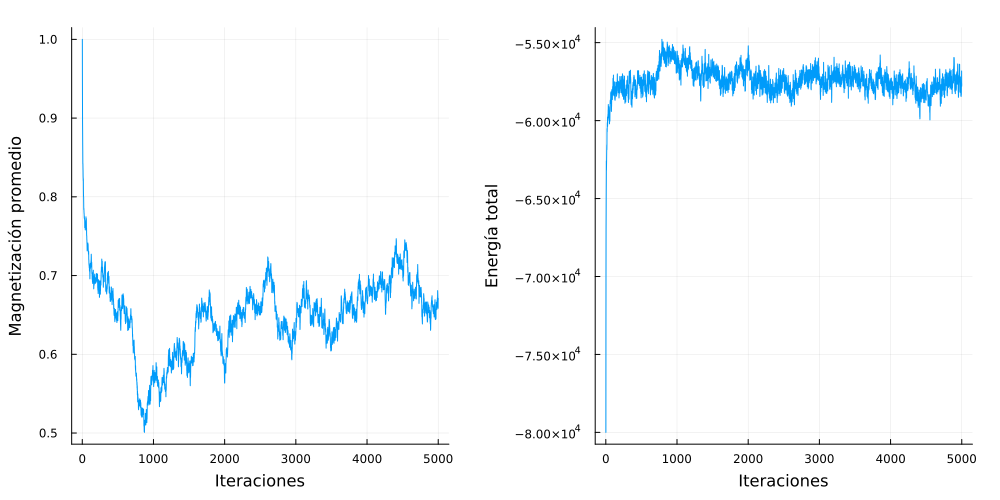

In [36]:
using Plots.PlotMeasures

#p_1 = plot(net_spins ./ N^2, xlabel="timesteps", ylabel="Magnetización promedio") #Esta es la magnetización promedio
#p_2 = plot(net_energy, xlabel="timesteps", ylabel="Energía total")

#plot(p_1, p_2, layout=(1, 2), size=(1000, 500), margin=5mm)

net_spins_sub  = (net_spins ./ N^2)[1:(N^2):end]
net_energy_sub = net_energy[1:(N^2):end]


p_1 = plot(net_spins_sub,  xlabel="Iteraciones", ylabel="Magnetización promedio", legend=false)
p_2 = plot(net_energy_sub, xlabel="Iteraciones", ylabel="Energía total", legend=false)

plot(p_1, p_2, layout=(1, 2), size=(1000, 500), margin=5mm)

351


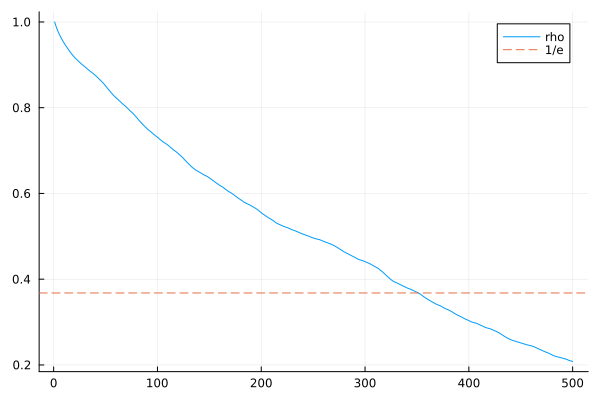

In [53]:
mag_time_series = (net_spins ./ N^2)[N^2:N^2:end]

autocov = sample_autocovariance(mag_time_series, 500)
auto_time = find_autocorrelation_time(autocov)



println(auto_time)
plot(range(1, 500), autocov ./ autocov[1], label="rho")
hline!([exp(-1)], linestyle=:dash, label="1/e")